In [25]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [26]:
pd.set_option('display.max_columns', None)
sns.set(style='whitegrid', palette='pastel')

In [27]:
df = pd.read_csv('german_credit_data.csv')

In [28]:
df.head()


,Unnamed: 0,Age,Sex,Job,Housing,Saving accounts,Checking account,Credit amount,Duration,Purpose,Risk
0,0,67,male,2,own,NaN,little,1169,6,radio/TV,good
1,1,22,female,2,own,little,moderate,5951,48,radio/TV,bad
2,2,49,male,1,own,little,NaN,2096,12,education,good
3,3,45,male,2,free,little,little,7882,42,furniture/equipment,good
4,4,53,male,2,free,little,little,4870,24,car,bad


In [29]:
df["Risk"].value_counts()

Risk
good    700
bad     300
Name: count, dtype: int64

In [30]:
df.shape

(1000, 11)

In [31]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 11 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Unnamed: 0        1000 non-null   int64
 1   Age               1000 non-null   int64
 2   Sex               1000 non-null   str  
 3   Job               1000 non-null   int64
 4   Housing           1000 non-null   str  
 5   Saving accounts   817 non-null    str  
 6   Checking account  606 non-null    str  
 7   Credit amount     1000 non-null   int64
 8   Duration          1000 non-null   int64
 9   Purpose           1000 non-null   str  
 10  Risk              1000 non-null   str  
dtypes: int64(5), str(6)
memory usage: 86.1 KB


In [32]:
df.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Unnamed: 0,1000.0,NaN,NaN,NaN,499.5,288.819436,0.0,249.75,499.5,749.25,999.0
Age,1000.0,NaN,NaN,NaN,35.546,11.375469,19.0,27.0,33.0,42.0,75.0
Sex,1000,2,male,690,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Job,1000.0,NaN,NaN,NaN,1.904,0.653614,0.0,2.0,2.0,2.0,3.0
Housing,1000,3,own,713,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Saving accounts,817,4,little,603,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Checking account,606,3,little,274,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Credit amount,1000.0,NaN,NaN,NaN,3271.258,2822.736876,250.0,1365.5,2319.5,3972.25,18424.0
Duration,1000.0,NaN,NaN,NaN,20.903,12.058814,4.0,12.0,18.0,24.0,72.0
Purpose,1000,8,car,337,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [33]:
df['Job'].unique()

array([2, 1, 3, 0])

In [34]:
df.isna().sum()

Unnamed: 0            0
Age                   0
Sex                   0
Job                   0
Housing               0
Saving accounts     183
Checking account    394
Credit amount         0
Duration              0
Purpose               0
Risk                  0
dtype: int64

In [35]:
df.duplicated().sum()

np.int64(0)

In [36]:
df["Saving accounts"].unique()

<StringArray>
[nan, 'little', 'quite rich', 'rich', 'moderate']
Length: 5, dtype: str

In [42]:
df["Checking account"].unique()

<StringArray>
['little', 'moderate', nan, 'rich']
Length: 4, dtype: str

In [43]:
df['Saving accounts'] = df['Saving accounts'].fillna('unknown')
df['Checking account'] = df['Checking account'].fillna('unknown')

In [44]:
df  

,Age,Sex,Job,Housing,Saving accounts,Checking account,Credit amount,Duration,Purpose,Risk
0,67,male,2,own,unknown,little,1169,6,radio/TV,good
1,22,female,2,own,little,moderate,5951,48,radio/TV,bad
2,49,male,1,own,little,unknown,2096,12,education,good
3,45,male,2,free,little,little,7882,42,furniture/equipment,good
4,53,male,2,free,little,little,4870,24,car,bad
...,...,...,...,...,...,...,...,...,...,...
995,31,female,1,own,little,unknown,1736,12,furniture/equipment,good
996,40,male,3,own,little,little,3857,30,car,good
997,38,male,2,own,little,unknown,804,12,radio/TV,good
998,23,male,2,free,little,little,1845,45,radio/TV,bad


In [38]:
df.columns

Index(['Unnamed: 0', 'Age', 'Sex', 'Job', 'Housing', 'Saving accounts',
       'Checking account', 'Credit amount', 'Duration', 'Purpose', 'Risk'],
      dtype='str')

In [39]:
df.drop(columns=['Unnamed: 0'], inplace=True)

/tmp/ipykernel_189088/4136117298.py:1: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop(columns=['Unnamed: 0'], inplace=True)


In [40]:
df.columns

Index(['Age', 'Sex', 'Job', 'Housing', 'Saving accounts', 'Checking account',
       'Credit amount', 'Duration', 'Purpose', 'Risk'],
      dtype='str')

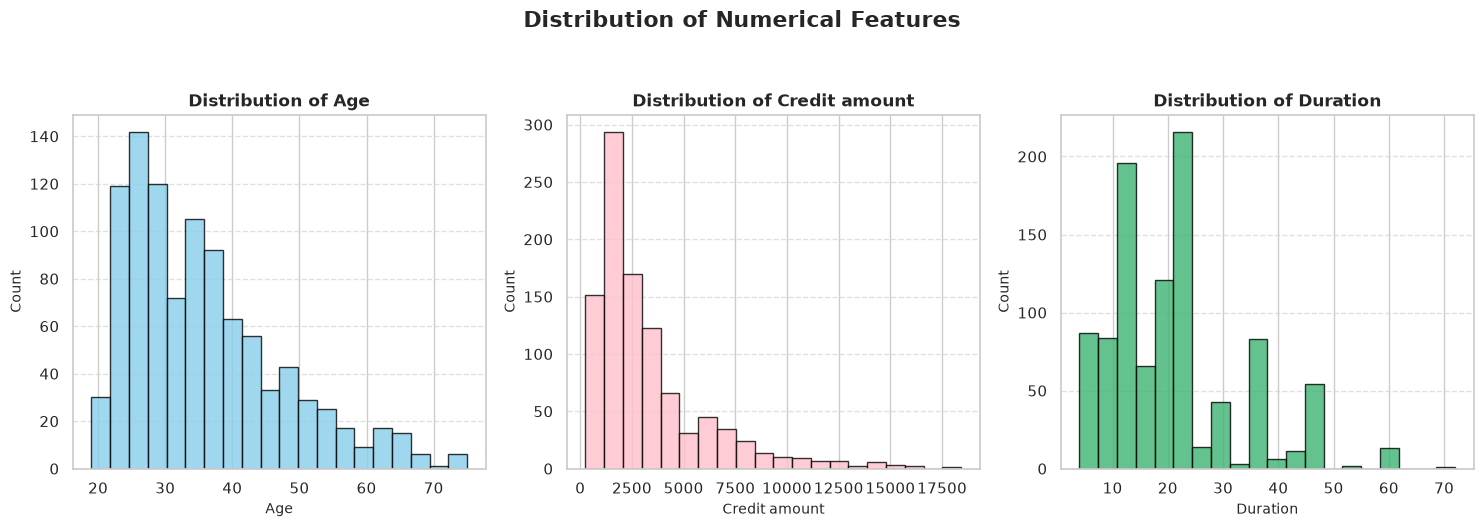

In [ ]:
# Create subplots for each feature
fig, axes = plt.subplots(1, 3, figsize=(15, 5))  

# Features to plot
features = ["Age", "Credit amount", "Duration"]
colors = ["skyblue", "pink", "mediumseagreen"]  

for ax, feature, color in zip(axes, features, colors):
    ax.hist(df[feature], bins=20, edgecolor="black", color=color, alpha=0.8)
    ax.set_title(f"Distribution of {feature}", fontsize=12, fontweight="bold")
    ax.set_xlabel(feature, fontsize=10)
    ax.set_ylabel("Count", fontsize=10)
    ax.grid(axis="y", linestyle="--", alpha=0.6)

# Main title
fig.suptitle("Distribution of Numerical Features", fontsize=16, fontweight="bold", y=1.05)

plt.tight_layout()
plt.show()

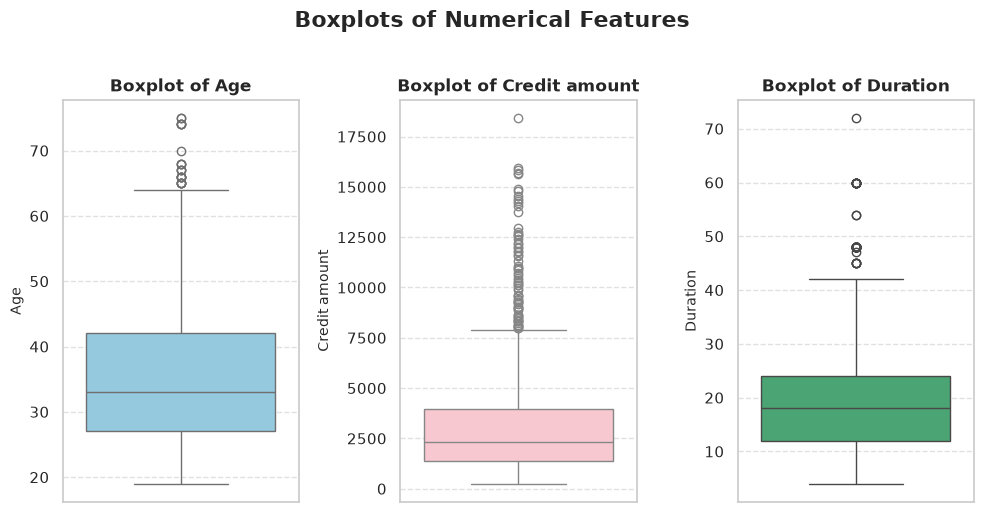

In [50]:
features = ["Age", "Credit amount", "Duration"]
colors = ["skyblue", "pink", "mediumseagreen"]  

plt.figure(figsize=(10, 5))  # wider layout

for i, (col, color) in enumerate(zip(features, colors)):
    plt.subplot(1, 3, i + 1)
    sns.boxplot(y=df[col], color=color)
    plt.title(f"Boxplot of {col}", fontsize=12, fontweight="bold")
    plt.ylabel(col, fontsize=10)
    plt.grid(axis="y", linestyle="--", alpha=0.6)

# Main title
plt.suptitle("Boxplots of Numerical Features", fontsize=16, fontweight="bold", y=1.02)

plt.tight_layout()
plt.show()

In [52]:
df.query("Duration >= 60")

,Age,Sex,Job,Housing,Saving accounts,Checking account,Credit amount,Duration,Purpose,Risk
29,63,male,2,own,little,little,6836,60,business,bad
134,21,female,2,own,moderate,unknown,10144,60,radio/TV,good
255,27,male,1,own,unknown,moderate,7418,60,radio/TV,good
332,24,female,3,own,moderate,moderate,7408,60,car,bad
373,63,male,3,free,unknown,unknown,13756,60,car,good
374,60,female,3,free,moderate,moderate,14782,60,vacation/others,bad
616,27,male,3,free,unknown,moderate,9157,60,radio/TV,good
637,21,male,2,own,little,unknown,15653,60,radio/TV,good
672,42,male,3,own,little,unknown,10366,60,car,good
677,24,male,2,own,moderate,moderate,5595,72,radio/TV,bad


In [53]:
categorical_cols = ["Sex", "Job", "Housing", "Saving accounts", "Checking account", "Purpose"]

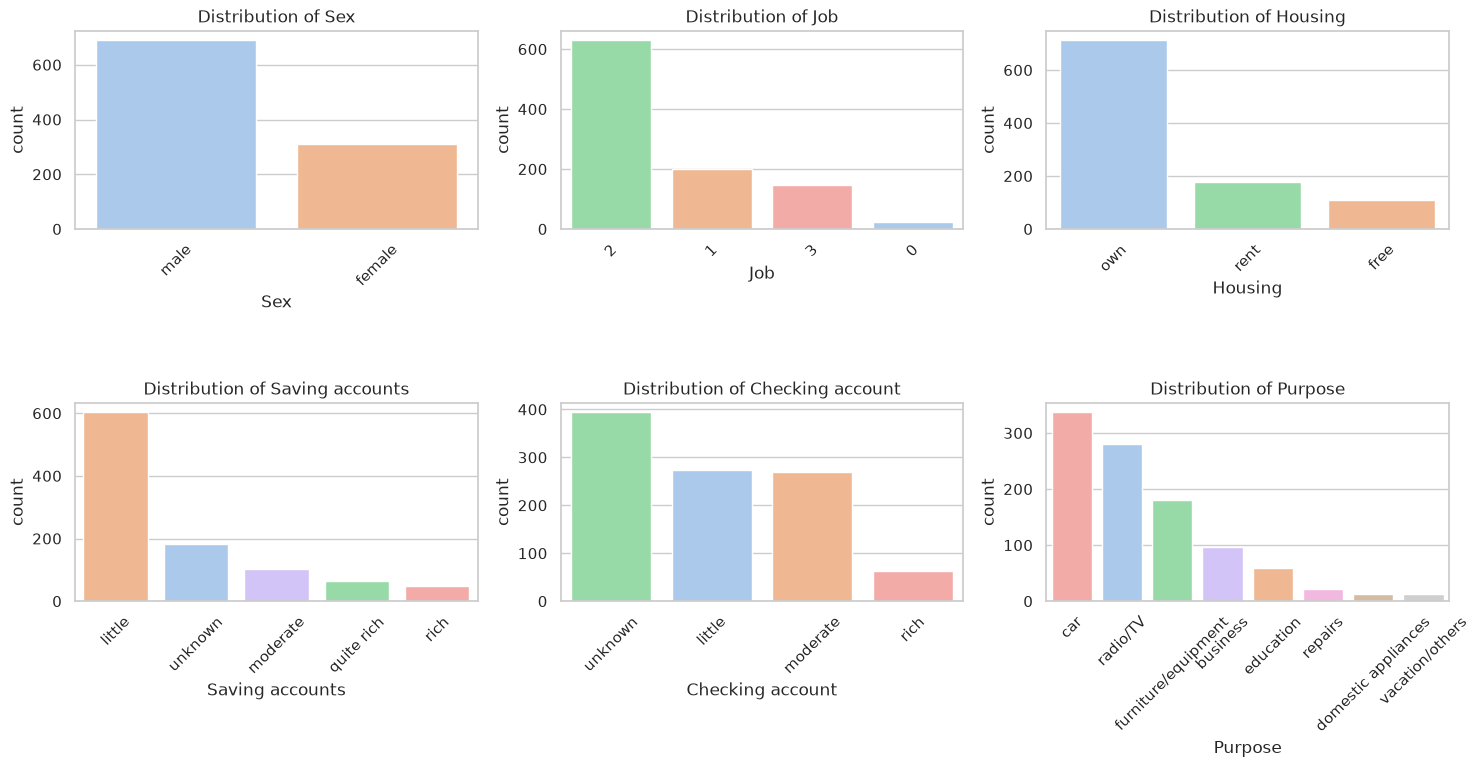

In [54]:
plt.figure(figsize=(15,10))

for i, col in enumerate(categorical_cols):
    plt.subplot(3, 3, i+1)
    sns.countplot(
        data=df,
        x=col,
        hue=col, 
        order=df[col].value_counts().index,
        palette="pastel",
        legend=False
    )
    plt.title(f"Distribution of {col}")
    plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [55]:
corr = df[["Age", "Job", "Credit amount", "Duration"]].corr()
corr

,Age,Job,Credit amount,Duration
Age,1.000000,0.015673,0.032716,-0.036136
Job,0.015673,1.000000,0.285385,0.210910
Credit amount,0.032716,0.285385,1.000000,0.624984
Duration,-0.036136,0.210910,0.624984,1.000000


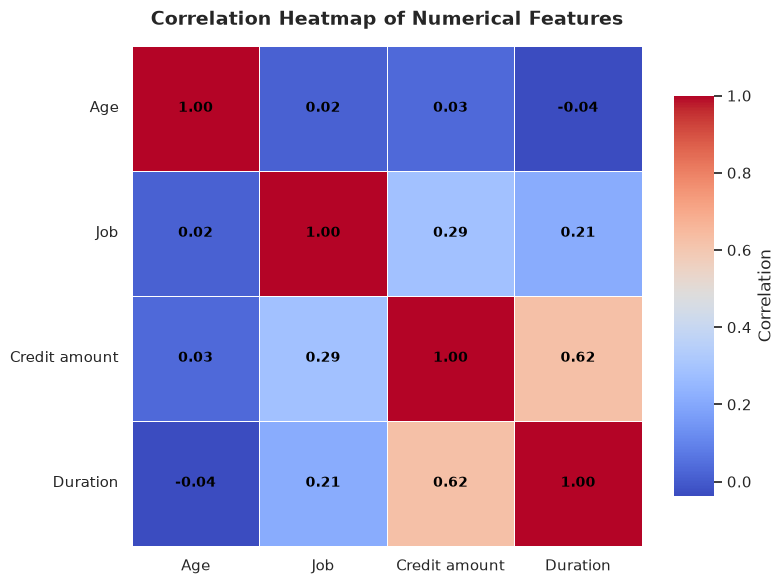

In [56]:
plt.figure(figsize=(8, 6))
sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",   
    fmt=".2f",
    linewidths=0.5,
    cbar_kws={"shrink": 0.8, "aspect": 10, "label": "Correlation"},
    annot_kws={"size": 10, "weight": "bold", "color": "black"} 
)

plt.title("Correlation Heatmap of Numerical Features", fontsize=14, fontweight="bold", pad=15)
plt.xticks(rotation=0)
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

In [57]:
df.groupby("Job")["Credit amount"].mean()

Job
0    2745.136364
1    2358.520000
2    3070.965079
3    5435.493243
Name: Credit amount, dtype: float64

In [58]:
df.groupby("Sex")["Credit amount"].mean()

Sex
female    2877.774194
male      3448.040580
Name: Credit amount, dtype: float64

In [59]:
pd.pivot_table(df, values = "Credit amount", index = "Housing", columns = "Purpose")

Purpose,business,car,domestic appliances,education,furniture/equipment,radio/TV,repairs,vacation/others
Housing,,,,,,,,
free,4931.800000,5834.181818,NaN,4387.266667,4100.181818,2417.333333,2750.666667,7227.250
own,3800.592105,3329.949772,1546.5,2198.647059,3107.459016,2540.493392,2866.000000,8700.375
rent,5614.125000,3487.968254,1255.5,2931.000000,2727.354167,2199.763158,1522.000000,NaN


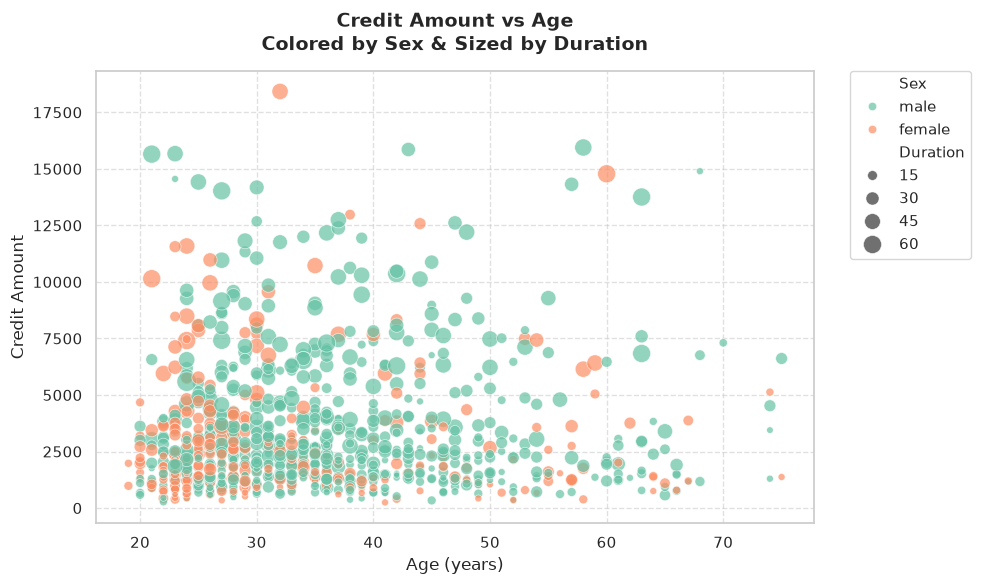

In [61]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="Age",
    y="Credit amount",
    hue="Sex",
    size="Duration",
    alpha=0.7,
    palette="Set2",
    sizes=(20, 200),  
    linewidth=0.5
)

plt.title("Credit Amount vs Age\nColored by Sex & Sized by Duration", fontsize=14, fontweight="bold", pad=15)
plt.xlabel("Age (years)", fontsize=12)
plt.ylabel("Credit Amount", fontsize=12)
plt.grid(True, linestyle="--", alpha=0.6)

# Place legend outside the plot
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left", borderaxespad=0)

plt.tight_layout()
plt.show()

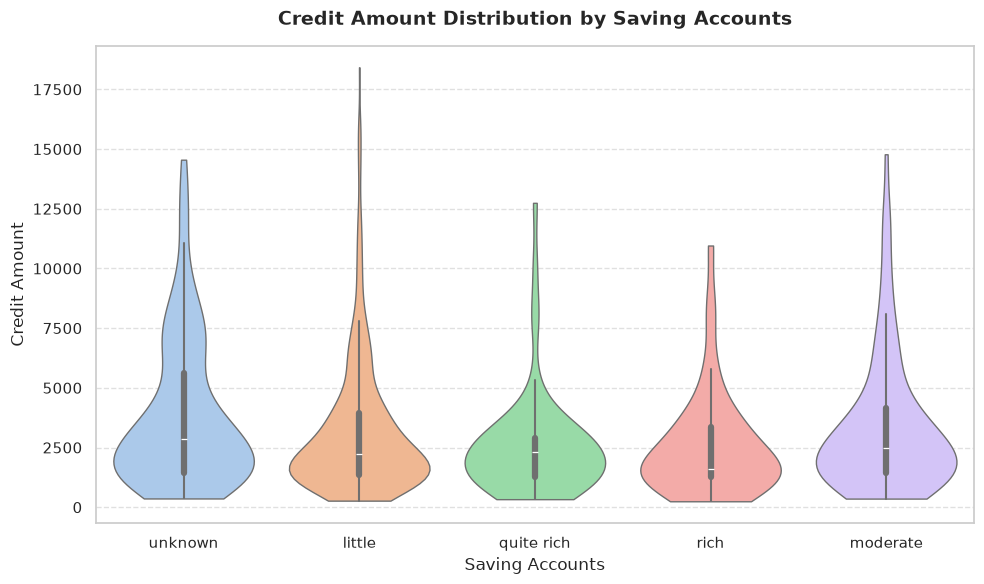

In [62]:
plt.figure(figsize=(10, 6))

sns.violinplot(
    data=df,
    x="Saving accounts",
    y="Credit amount",
    hue="Saving accounts",
    palette="pastel",        
    inner="box",            
    cut=0,                  
    linewidth=1
)

plt.title("Credit Amount Distribution by Saving Accounts", fontsize=14, fontweight="bold", pad=15)
plt.xlabel("Saving Accounts", fontsize=12)
plt.ylabel("Credit Amount", fontsize=12)
plt.grid(axis="y", linestyle="--", alpha=0.6)

plt.tight_layout()
plt.show()

In [63]:
df["Risk"].value_counts(normalize = True)*100

Risk
good    70.0
bad     30.0
Name: proportion, dtype: float64

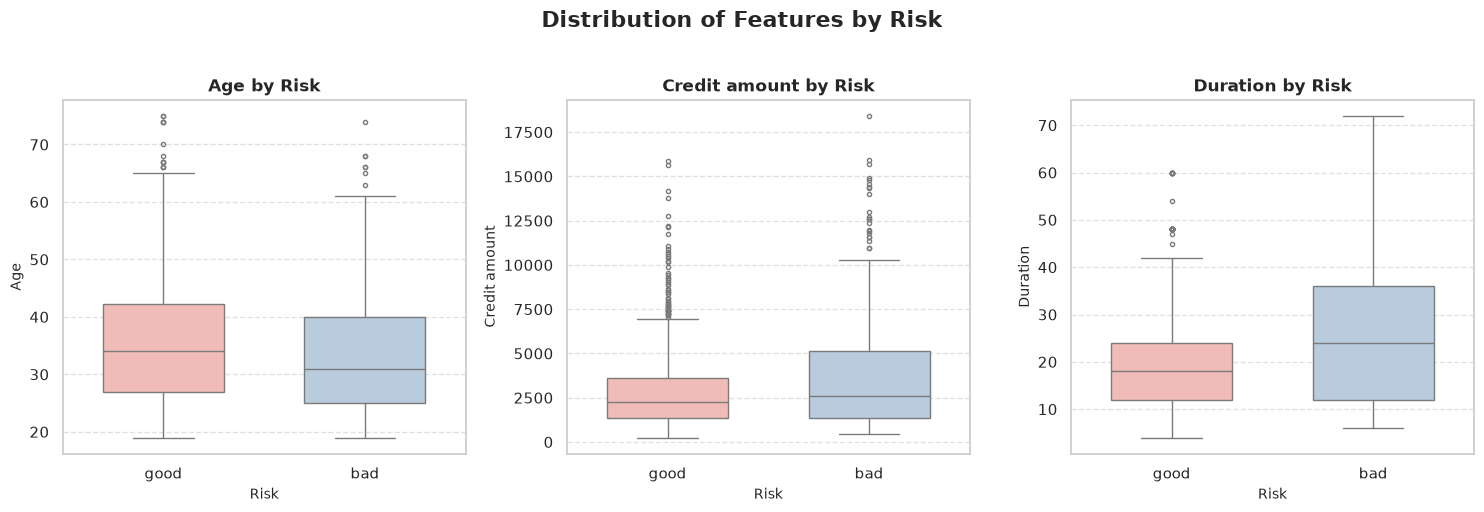

In [64]:
features = ["Age", "Credit amount", "Duration"]
colors = "Set2"  

plt.figure(figsize=(15, 5))

for i, col in enumerate(features):
    plt.subplot(1, 3, i + 1)
    sns.boxplot(
        data=df,
        x="Risk",
        y=col,
        hue="Risk",       
        palette="Pastel1",
        dodge=False,       
        width=0.6,
        fliersize=3
    )
    plt.title(f"{col} by Risk", fontsize=12, fontweight="bold")
    plt.xlabel("Risk", fontsize=10)
    plt.ylabel(col, fontsize=10)
    plt.grid(axis="y", linestyle="--", alpha=0.6)
    plt.legend([], [], frameon=False)  # remove redundant legend

# Main title
plt.suptitle("Distribution of Features by Risk", fontsize=16, fontweight="bold", y=1.02)

plt.tight_layout()
plt.show()

In [65]:
df.groupby("Risk")[["Age", "Credit amount", "Duration"]].mean()

,Age,Credit amount,Duration
Risk,,,
bad,33.963333,3938.126667,24.860000
good,36.224286,2985.457143,19.207143


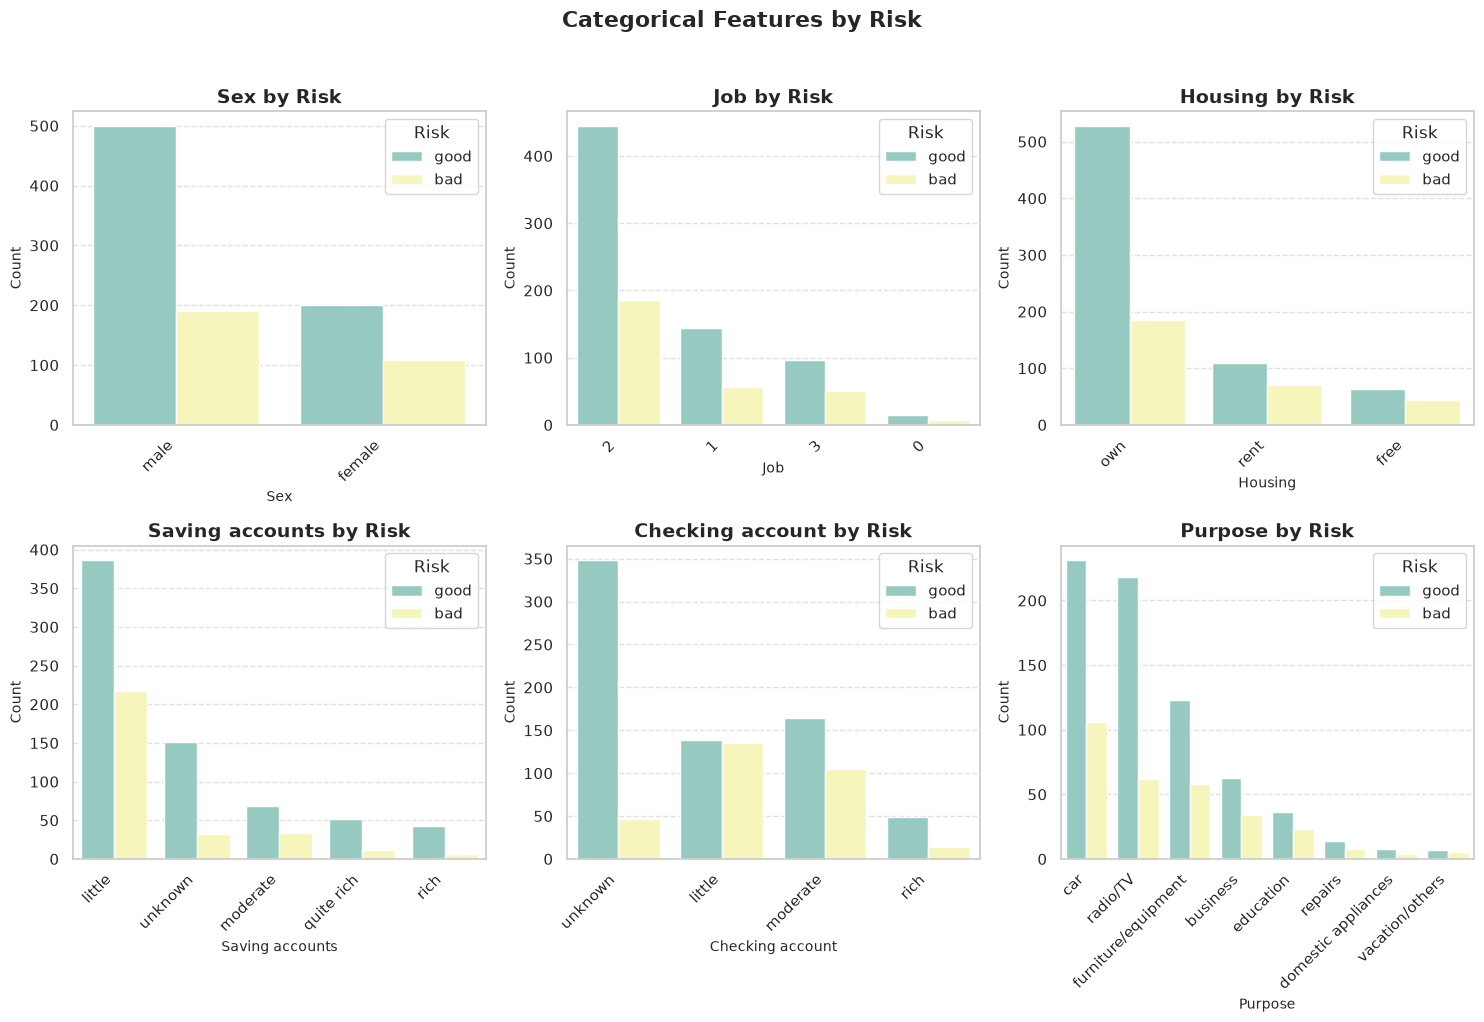

In [70]:
import math

n = len(categorical_cols)
rows = math.ceil(n / 3)  

plt.figure(figsize=(15, 5 * rows))  

for i, col in enumerate(categorical_cols, 1):
    plt.subplot(rows, 3, i)
    sns.countplot(
        data=df,
        x=col,
        hue="Risk",
        palette="Set3",
        order=df[col].value_counts().index
    )
    plt.title(f"{col} by Risk", fontsize=14, fontweight="bold")
    plt.xlabel(col, fontsize=10)
    plt.ylabel("Count", fontsize=10)
    plt.xticks(rotation=45, ha="right")
    plt.grid(axis="y", linestyle="--", alpha=0.6)

plt.suptitle("Categorical Features by Risk", fontsize=16, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()


In [71]:
df.columns

Index(['Age', 'Sex', 'Job', 'Housing', 'Saving accounts', 'Checking account',
       'Credit amount', 'Duration', 'Purpose', 'Risk'],
      dtype='str')

In [72]:
features = ['Age', 'Sex', 'Job', 'Housing', 'Saving accounts', 'Checking account','Credit amount', 'Duration']

In [73]:
target = 'Risk'

In [74]:
df_model = df[features + [target]].copy()

In [75]:
df_model.head()

,Age,Sex,Job,Housing,Saving accounts,Checking account,Credit amount,Duration,Risk
0,67,male,2,own,unknown,little,1169,6,good
1,22,female,2,own,little,moderate,5951,48,bad
2,49,male,1,own,little,unknown,2096,12,good
3,45,male,2,free,little,little,7882,42,good
4,53,male,2,free,little,little,4870,24,bad


In [76]:
from sklearn.preprocessing import LabelEncoder
import joblib

In [77]:
cat_cols = df_model.select_dtypes(include = 'object').columns.drop("Risk")

/tmp/ipykernel_189088/1770561580.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = df_model.select_dtypes(include = 'object').columns.drop("Risk")


In [78]:
le_dict = {}

In [79]:
cat_cols

Index(['Sex', 'Housing', 'Saving accounts', 'Checking account'], dtype='str')

In [81]:
for col in cat_cols:
    le = LabelEncoder()
    df_model[col] = le.fit_transform(df_model[col])
    le_dict[col] = le
    joblib.dump(le, f"{col}_encoder.pkl")

In [82]:
le_target = LabelEncoder()

In [83]:
df_model[target] = le_target.fit_transform(df_model[target])

In [84]:
df_model[target].value_counts()

Risk
1    700
0    300
Name: count, dtype: int64

In [85]:
joblib.dump(le_target, "target_encoder.pkl")

['target_encoder.pkl']

In [86]:
from sklearn.model_selection import train_test_split

In [87]:
X = df_model.drop(target, axis = 1)
Y = df_model[target]

In [88]:
X

,Age,Sex,Job,Housing,Saving accounts,Checking account,Credit amount,Duration
0,67,1,2,1,4,0,1169,6
1,22,0,2,1,0,1,5951,48
2,49,1,1,1,0,3,2096,12
3,45,1,2,0,0,0,7882,42
4,53,1,2,0,0,0,4870,24
...,...,...,...,...,...,...,...,...
995,31,0,1,1,0,3,1736,12
996,40,1,3,1,0,0,3857,30
997,38,1,2,1,0,3,804,12
998,23,1,2,0,0,0,1845,45


In [89]:
Y

0      1
1      0
2      1
3      1
4      0
      ..
995    1
996    1
997    1
998    0
999    1
Name: Risk, Length: 1000, dtype: int64

In [94]:
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, stratify=Y, test_size=0.2, random_state=42)

In [95]:
X_train.shape, X_test.shape

((800, 8), (200, 8))

In [99]:
from imblearn.over_sampling import SMOTE

smote = SMOTE(random_state=42)
X_train, Y_train = smote.fit_resample(X_train, Y_train)

In [97]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score
from sklearn.model_selection import GridSearchCV

In [100]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score
from sklearn.model_selection import GridSearchCV

def train_model(model, param_grid, X_train, X_test, Y_train, Y_test):
    grid = GridSearchCV(model, param_grid, cv = 5, scoring = 'accuracy', n_jobs = -1)
    grid.fit(X_train, Y_train)
    best_model = grid.best_estimator_
    Y_pred = best_model.predict(X_test)
    acc = accuracy_score(Y_test, Y_pred)
    return best_model, acc, grid.best_params_


In [101]:
dt = DecisionTreeClassifier(random_state = 42, class_weight = 'balanced')
dt_param_grid = {
    "max_depth" : [3, 5, 7, 10, None],
    "min_samples_split" : [2, 5, 10],
    "min_samples_leaf" : [1, 2, 4]
}

In [102]:
best_dt, acc_dt, params_dt = train_model(dt, dt_param_grid, X_train, X_test, Y_train, Y_test)

0.01s - Debugger warning: It seems that frozen modules are being used, which may
0.00s - make the debugger miss breakpoints. Please pass -Xfrozen_modules=off
0.00s - to python to disable frozen modules.
0.00s - Note: Debugging will proceed. Set PYDEVD_DISABLE_FILE_VALIDATION=1 to disable this validation.
0.00s - Debugger warning: It seems that frozen modules are being used, which may
0.00s - make the debugger miss breakpoints. Please pass -Xfrozen_modules=off
0.00s - to python to disable frozen modules.
0.00s - Note: Debugging will proceed. Set PYDEVD_DISABLE_FILE_VALIDATION=1 to disable this validation.
0.01s - Debugger warning: It seems that frozen modules are being used, which may
0.00s - make the debugger miss breakpoints. Please pass -Xfrozen_modules=off
0.00s - to python to disable frozen modules.
0.00s - Note: Debugging will proceed. Set PYDEVD_DISABLE_FILE_VALIDATION=1 to disable this validation.
0.01s - Debugger warning: It seems that frozen modules are being used, which may
0

In [103]:
print('Decision Tree Accuracy:', acc_dt)

Decision Tree Accuracy: 0.665


In [104]:
print('Best parameters', params_dt)

Best parameters {'max_depth': 10, 'min_samples_leaf': 4, 'min_samples_split': 2}


In [105]:
rf = RandomForestClassifier(random_state = 42, class_weight = 'balanced', n_jobs = -1)

In [106]:
rf_param_grid = {
    "n_estimators" : [100, 150, 200],
    "max_depth" : [5, 7, 10, None],
    "min_samples_split" : [2, 5, 10],
    "min_samples_leaf" : [1, 2, 4]
}

In [108]:
best_rf, acc_rf, params_rf = train_model(rf, rf_param_grid, X_train, X_test, Y_train, Y_test)

In [109]:
print('Random Forest Accuracy:', acc_rf)

Random Forest Accuracy: 0.76


In [110]:
print('Best parameters', params_rf)

Best parameters {'max_depth': None, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 100}


In [111]:
et = ExtraTreesClassifier(random_state = 42, class_weight = 'balanced', n_jobs = -1)

In [112]:
et_param_grid = {
    "n_estimators" : [100, 150, 200],
    "max_depth" : [5, 7, 10, None],
    "min_samples_split" : [2, 5, 10],
    "min_samples_leaf" : [1, 2, 4]
}

In [114]:
best_et, acc_et, params_et = train_model(et, et_param_grid, X_train, X_test, Y_train, Y_test)

In [115]:
print('Extra Trees Accuracy:', acc_et)

Extra Trees Accuracy: 0.715


In [116]:
print('Best parameters', params_et)

Best parameters {'max_depth': 10, 'min_samples_leaf': 1, 'min_samples_split': 5, 'n_estimators': 200}


In [118]:
xgb = XGBClassifier(random_state = 42, scale_pos_weight = (Y_train == 0).sum() / (Y_train == 1).sum(), eval_metric = 'logloss')

In [119]:
xgb_param_grid = {
    "n_estimators" : [100, 150, 200],
    "max_depth" : [3, 5, 7],
    "learning_rate" : [0.01, 0.1, 0.2, 0.5],
    "subsample" : [0.5, 0.7, 1],
    "colsample_bytree" : [0.5, 0.7, 1]
}

In [121]:
best_xgb, acc_xgb, params_xgb = train_model(xgb, xgb_param_grid, X_train, X_test, Y_train, Y_test)

In [122]:
print('XGB Accuracy:', acc_xgb)

XGB Accuracy: 0.75


In [123]:
print('Best parameters', params_xgb)

Best parameters {'colsample_bytree': 0.7, 'learning_rate': 0.2, 'max_depth': 5, 'n_estimators': 150, 'subsample': 1}


In [124]:
best_xgb.predict(X_test)

array([1, 0, 1, 1, 0, 1, 1, 1, 0, 1, 1, 1, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1,
       0, 1, 1, 0, 1, 0, 1, 0, 1, 1, 1, 1, 0, 0, 0, 1, 1, 0, 1, 1, 1, 0,
       1, 0, 1, 1, 0, 1, 1, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 0, 1,
       1, 1, 1, 1, 1, 0, 1, 0, 1, 0, 1, 1, 1, 0, 0, 0, 1, 0, 1, 1, 0, 1,
       1, 1, 0, 1, 0, 1, 1, 1, 1, 0, 0, 0, 1, 0, 1, 0, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 0, 1, 1, 1, 0, 0, 1, 1, 1, 1, 0,
       1, 1, 0, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 0, 1, 1, 1, 0, 0, 1, 1, 1,
       1, 1, 1, 1, 1, 0, 0, 1, 0, 1, 1, 1, 0, 0, 0, 1, 0, 1, 0, 0, 1, 0,
       1, 1, 1, 0, 0, 1, 1, 0, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 1, 0, 0,
       1, 0])

In [125]:
from sklearn.linear_model import LogisticRegression

In [126]:
log_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

In [127]:
log_model.fit(X_train, Y_train)

,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in 

In [128]:
y_pred_log = log_model.predict(X_test)

y_prob_log = log_model.predict_proba(X_test)[:, 1]

In [129]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

print("Accuracy:", accuracy_score(Y_test, y_pred_log))
print("Precision:", precision_score(Y_test, y_pred_log))
print("Recall:", recall_score(Y_test, y_pred_log))
print("F1 Score:", f1_score(Y_test, y_pred_log))
print("ROC-AUC:", roc_auc_score(Y_test, y_prob_log))

Accuracy: 0.685
Precision: 0.8407079646017699
Recall: 0.6785714285714286
F1 Score: 0.7509881422924901
ROC-AUC: 0.7364285714285714


In [130]:
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, RocCurveDisplay
import matplotlib.pyplot as plt

# Predictions
y_pred_rf = best_rf.predict(X_test)
y_pred_xgb = best_xgb.predict(X_test)

# Probabilities (needed for ROC-AUC)
y_prob_rf = best_rf.predict_proba(X_test)[:, 1]
y_prob_xgb = best_xgb.predict_proba(X_test)[:, 1]

# Print Accuracy
print("Random Forest Accuracy:", acc_rf)
print("XGBoost Accuracy:", acc_xgb)
print("Logistic Regression Accuracy:", accuracy_score(Y_test, y_pred_log))
# Print Classification Reports
print("\nRandom Forest Classification Report:\n", classification_report(Y_test, y_pred_rf))
print("XGBoost Classification Report:\n", classification_report(Y_test, y_pred_xgb))
print("\nLogistic Regression Classification Report:\n", classification_report(Y_test, y_pred_log))



Random Forest Accuracy: 0.76
XGBoost Accuracy: 0.75
Logistic Regression Accuracy: 0.685

Random Forest Classification Report:
               precision    recall  f1-score   support

           0       0.58      0.70      0.64        60
           1       0.86      0.79      0.82       140

    accuracy                           0.76       200
   macro avg       0.72      0.74      0.73       200
weighted avg       0.78      0.76      0.77       200

XGBoost Classification Report:
               precision    recall  f1-score   support

           0       0.58      0.62      0.60        60
           1       0.83      0.81      0.82       140

    accuracy                           0.75       200
   macro avg       0.70      0.71      0.71       200
weighted avg       0.76      0.75      0.75       200


Logistic Regression Classification Report:
               precision    recall  f1-score   support

           0       0.48      0.70      0.57        60
           1       0.84      0.68

In [131]:

# Confusion Matrices
print("Random Forest Confusion Matrix:\n", confusion_matrix(Y_test, y_pred_rf))
print("\nXGBoost Confusion Matrix:\n", confusion_matrix(Y_test, y_pred_xgb))
print("\nLogistic Regression Confusion Matrix:\n", confusion_matrix(Y_test, y_pred_log))

# ROC-AUC Scores
roc_auc_rf = roc_auc_score(Y_test, y_prob_rf)
roc_auc_xgb = roc_auc_score(Y_test, y_prob_xgb)
roc_auc_log = roc_auc_score(Y_test, y_prob_log)

print("\nRandom Forest ROC-AUC:", roc_auc_rf)
print("XGBoost ROC-AUC:", roc_auc_xgb)
print("Logistic Regression ROC-AUC:", roc_auc_log)



Random Forest Confusion Matrix:
 [[ 42  18]
 [ 30 110]]

XGBoost Confusion Matrix:
 [[ 37  23]
 [ 27 113]]

Logistic Regression Confusion Matrix:
 [[42 18]
 [45 95]]

Random Forest ROC-AUC: 0.7678571428571429
XGBoost ROC-AUC: 0.7546428571428572
Logistic Regression ROC-AUC: 0.7364285714285714


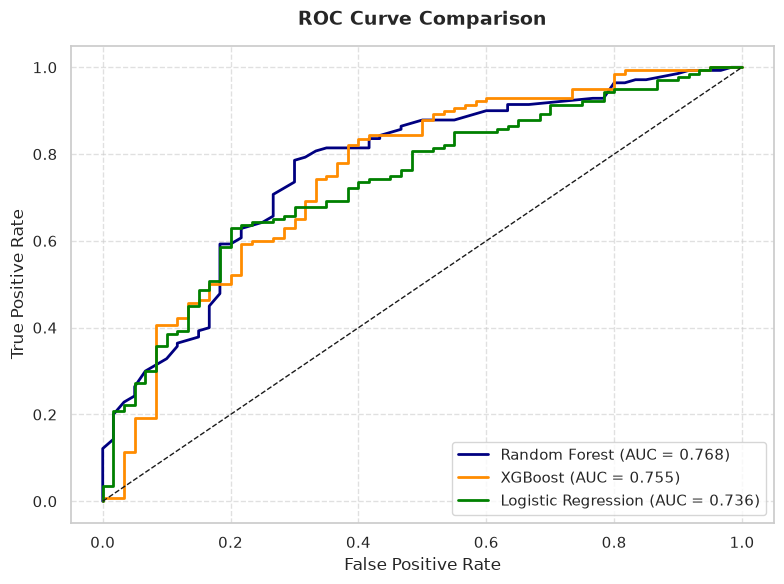

In [135]:

from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

# Calculate ROC values
fpr_rf, tpr_rf, _ = roc_curve(Y_test, best_rf.predict_proba(X_test)[:, 1])
fpr_xgb, tpr_xgb, _ = roc_curve(Y_test, best_xgb.predict_proba(X_test)[:, 1])
fpr_log, tpr_log, _ = roc_curve(Y_test, log_model.predict_proba(X_test)[:, 1])

# Plot ROC curves
plt.plot(fpr_rf, tpr_rf, color="navy", linewidth=2,
         label=f"Random Forest (AUC = {auc(fpr_rf, tpr_rf):.3f})")

plt.plot(fpr_xgb, tpr_xgb, color="darkorange", linewidth=2,
         label=f"XGBoost (AUC = {auc(fpr_xgb, tpr_xgb):.3f})")

plt.plot(fpr_log, tpr_log, color="green", linewidth=2,
         label=f"Logistic Regression (AUC = {auc(fpr_log, tpr_log):.3f})")

# Reference diagonal
plt.plot([0, 1], [0, 1], "k--", linewidth=1)

# Titles and labels
plt.title("ROC Curve Comparison", fontsize=14, fontweight="bold", pad=15)
plt.xlabel("False Positive Rate", fontsize=12)
plt.ylabel("True Positive Rate", fontsize=12)

plt.grid(linestyle="--", alpha=0.6)
plt.legend(loc="lower right")

plt.tight_layout()
plt.show()


In [136]:
joblib.dump(best_rf, "random_forest_credit_model.pkl")

['random_forest_credit_model.pkl']